## Individuell uppgift – Hälsostudie

### Del 1 – Grundläggande analys och statistik

#### Analys av hälsodata med beskrivande statistik, simulering, konfidensintervall och hypotesprövning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

In [2]:
df = pd.read_csv("health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [4]:
print(df.isna().sum())
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["disease"].value_counts())

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64
disease
0    753
1     47
Name: count, dtype: int64


## Översikt av datan

Datasetet innehåller 800 deltagare och 9 kolumner. Det finns inga saknade värden, så ingen datarensning behövs. Kolumnerna sex och smoker är kategoriska (text). Kolumnen disease lagras som siffror (0/1) men är också kategorisk: 1 betyder att personen har sjukdomen. Kolumnen id är bara ett löpnummer och används inte i analysen. Övriga kolumner är numeriska.

In [5]:
## Beskrivande analys för age, weight, height, systolic_bp, cholesterol

cols = ["age","weight","height","systolic_bp","cholesterol"]
summary = df[cols].agg(["mean","median","min","max"]).round(2)
summary

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


### Tolkning av beskrivande statistik

Medelvärde och median ligger mycket nära varandra för alla variabler, till exempel 149,2 och 149,4 mmHg för blodtryck. Det tyder på att fördelningarna är ungefär symmetriska utan stora extremvärden som drar medelvärdet åt ett håll.

Deltagarna är mellan 18 och 90 år, med en medelålder på cirka 49 år. Längd och vikt ligger inom rimliga intervall, men den lägsta vikten (33,7 kg) är ovanligt låg för en vuxen och kan vara ett extremvärde.

Medelvärdet för systoliskt blodtryck är cirka 149 mmHg, vilket är över den vanliga gränsen för högt blodtryck (cirka 140 mmHg). Deltagarna har alltså i genomsnitt förhöjt blodtryck. 

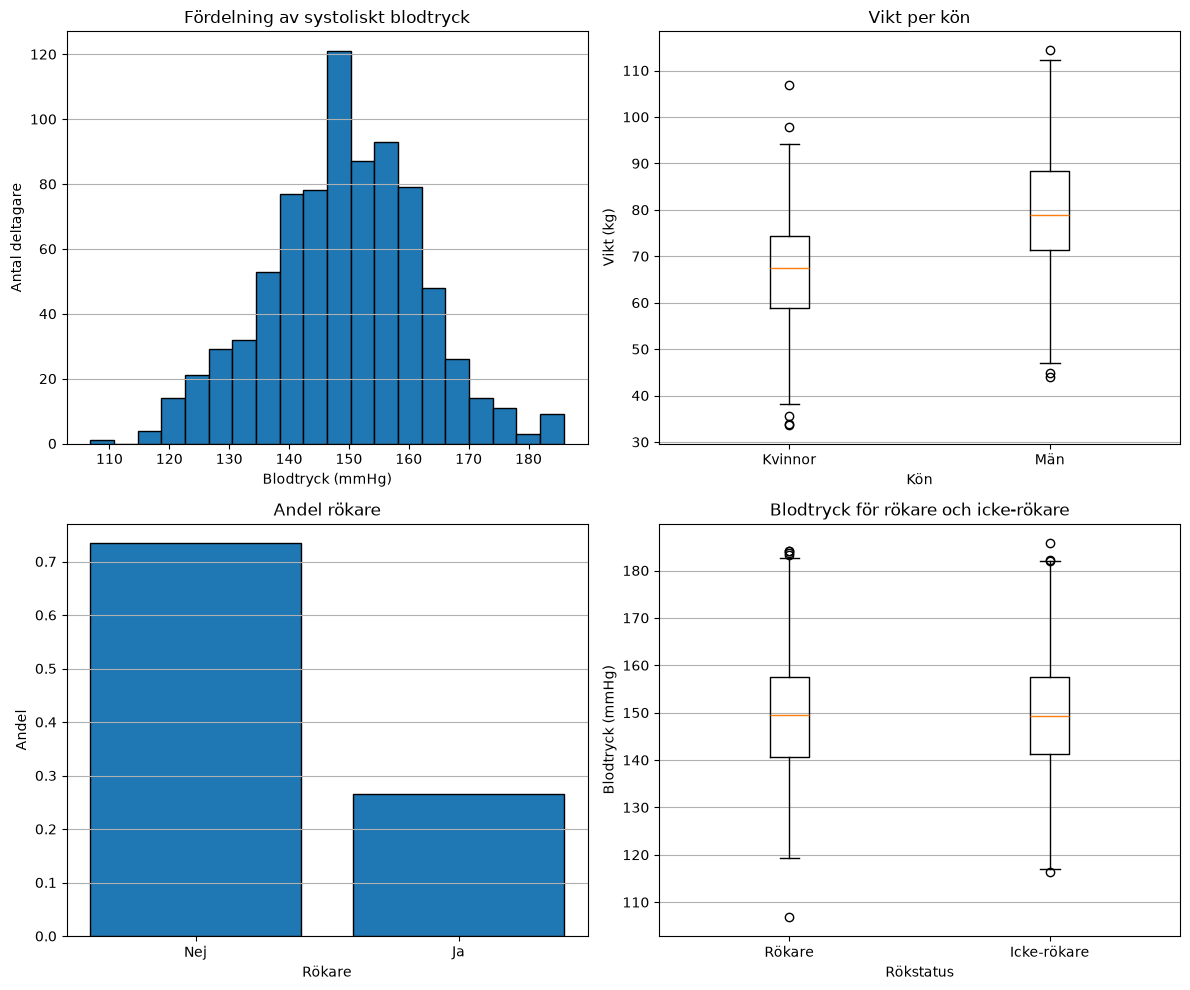

In [6]:
## Visualisering

fig, axes = plt.subplots(2, 2, figsize = (12,10), sharex=False, sharey = False)

## Histogram över blodtryck

axes[0,0].hist(df["systolic_bp"], bins = 20, edgecolor = "black")
axes[0,0].set_title("Fördelning av systoliskt blodtryck")
axes[0,0].set_xlabel("Blodtryck (mmHg)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y")

## Boxplot över vikt per kön

axes[0,1].boxplot([df.loc[df["sex"] == "F", "weight"], df.loc[df["sex"] == "M", "weight"]], tick_labels=["Kvinnor", "Män"])
axes[0,1].set_title("Vikt per kön")
axes[0,1].set_xlabel("Kön")
axes[0,1].set_ylabel("Vikt (kg)")
axes[0,1].grid(True, axis = "y")

## Stapeldiagram över andelen rökare

smoker_share = df["smoker"].value_counts(normalize=True).rename({"No":"Nej", "Yes":"Ja"})
axes[1, 0].bar(smoker_share.index, smoker_share.values, edgecolor="black")
axes[1, 0].set_title("Andel rökare")
axes[1, 0].set_xlabel("Rökare")
axes[1, 0].set_ylabel("Andel")
axes[1, 0].grid(True, axis="y")

## Boxplot över blodtryck för rökare och icke-rökare

axes[1,1].boxplot([df.loc[df["smoker"] == "Yes", "systolic_bp"], df.loc[df["smoker"] == "No","systolic_bp"]], tick_labels = ["Rökare","Icke-rökare"])
axes[1,1].set_title("Blodtryck för rökare och icke-rökare")
axes[1,1].set_xlabel("Rökstatus")
axes[1,1].set_ylabel("Blodtryck (mmHg)")              
axes[1,1].grid(True, axis = "y")

plt.tight_layout()
plt.show()


### Tolkning av graferna

**Histogram:** Blodtrycket är ungefär normalfördelat, med de flesta deltagarna kring 145–155 mmHg. Det stämmer med att medelvärde och median ligger nära varandra.

**Vikt per kön:** Män väger i genomsnitt mer än kvinnor (median cirka 79 kg mot 67 kg). Båda grupperna har några extremvärden, bland annat den låga vikten på 33,7 kg.

**Andel rökare:** Cirka 27 % av deltagarna röker och 73 % röker inte. Grupperna är alltså olika stora.

**Blodtryck för rökare och icke-rökare:** Boxplottarna är nästan identiska, med median kring 149–150 mmHg i båda grupperna. Det finns ingen tydlig skillnad i grafen, men det undersöks närmare med en hypotesprövning senare.

In [7]:
## Simulering av sjukdomsandel

p_disease = df["disease"].mean()
print(f"Verklig andel: {p_disease:.4f}")

Verklig andel: 0.0587


In [8]:
simulated = rng.random(1000) < p_disease
p_sim = simulated.mean()

print(f"Simulerad andel:{p_sim:.4f}")
print(f"Differens: {p_sim - p_disease:.4f}")

Simulerad andel:0.0650
Differens: 0.0063


In [9]:
se_sim = np.sqrt(p_disease*(1-p_disease)/1000)
print(f"Förväntat standardfel: {se_sim:.4f}")

Förväntat standardfel: 0.0074


### Tolkning av simuleringen

Den verkliga andelen deltagare med sjukdomen är 0,0587, alltså cirka 5,9 %. I simuleringen av 1000 personer blev andelen 0,065, alltså 6,5 %. Skillnaden mellan den simulerade och den verkliga andelen är bara 0,0063.

Skillnaden är mindre än det förväntade standardfelet (0,0074), vilket betyder att den ligger inom normal slumpvariation. Andelarna blir inte exakt lika eftersom varje simulerad person får sjukdomen slumpmässigt, med sannolikheten 0,0587. Med fler simulerade personer, till exempel 100 000 istället för 1000, skulle skillnaden bli ännu mindre.

In [10]:
## Konfidensintervall för medelvärdet av systolic_bp - med normalapproximation 

bp = df["systolic_bp"]

def ci_mean_normal(bp, confidence=0.95):
    """
    95% _CI för medel värde med normal-approximation:
    medel ± 1.96*(sd/sqrt(n))
    """

    bp=np.asarray(bp, dtype=float)
    mean_bp = float(np.mean(bp))
    sd_bp = float(np.std(bp, ddof=1))
    n = len(bp)

    z_critical=1.96
    half_width = (z_critical*sd_bp) / np.sqrt(n)  
    lo, hi = mean_bp -half_width, mean_bp + half_width
    return lo, hi, mean_bp, sd_bp, n

lo, hi, mean_bp, sd_bp, n = ci_mean_normal(bp)

print(f"Medelvärde:{mean_bp: .2f} mmHg")
print(f"Standardavvikelse:{sd_bp:.2f} mmHg")
print(f"n = {n}")
print(f"95% KI(normalapprox.):{lo: .2f} -{hi: .2f} mmHg")

Medelvärde: 149.18 mmHg
Standardavvikelse:12.79 mmHg
n = 800
95% KI(normalapprox.): 148.29 - 150.07 mmHg


### Tolkning av konfidensintervallet

Medelvärdet för systoliskt blodtryck är 149,18 mmHg. Vi är 95 % säkra på att det sanna medelvärdet för systoliskt blodtryck i populationen ligger mellan 148,29 och 150,07 mmHg.

Intervallet är smalt eftersom stickprovet är stort (n = 800). Standardfelet (sd / √n) blir mindre när stickprovet blir större.

Jag använder 95 % konfidensnivå eftersom det är standard inom forskning och motsvarar signifikansnivån α = 0,05 som används i hypotesprövningen.

In [11]:
## Konfidensintervall för medelvärdet av systolic_bp - med med bootstrapmetoden.

bp = df["systolic_bp"]

def ci_mean_bootstrap(bp, B=10000, confidence=0.95):
    bp = np.asarray(bp, dtype = float)
    n = len(bp)
    boot_means = np.empty(B)
    for b in range(B):
        boot_sample = rng.choice(bp, size = n, replace = True)
        boot_means[b] = np.mean(boot_sample)

    alpha = (1 - confidence) / 2
    lo, hi = np.percentile(boot_means, [100*alpha, 100*(1-alpha)])
    return float (lo), float(hi), float(np.mean(bp)), boot_means 

blo, bhi, bmean, boot_means = ci_mean_bootstrap(bp)

print(f"95% KI (bootstrap): {blo:.2f}-{bhi:.2f} mmHg")
print(f"95% KI (normalapprox): {lo:.2f}-{hi:.2f} mmHg")




95% KI (bootstrap): 148.31-150.07 mmHg
95% KI (normalapprox): 148.29-150.07 mmHg


### Jämförelse av metoderna

Båda metoderna ger samma nedre gräns, 148,29 mmHg, medan den övre gränsen bara skiljer sig med 0,02 mmHg (150,07 mot 150,09 mmHg). Metoderna ger alltså i praktiken samma resultat.

Normalapproximationen bygger på en formel och antar att stickprovsmedelvärdet är normalfördelat. Bootstrap gör inget sådant antagande, utan drar istället 10 000 nya stickprov med återläggning från datan och använder fördelningen av deras medelvärden.

Att metoderna ger nästan samma intervall visar att normalapproximationens antagande håller här. Det beror på att stickprovet är stort (n = 800), så att centrala gränsvärdessatsen gäller, och att blodtrycket är ungefär symmetriskt fördelat, vilket syns i histogrammet.